# POM simulator

## Library configuration

In [1]:
# everything is setup in epvid.py
from epvid import *

MIEPOM backend set to mlx.core
eptraj: Using single precision


## Microscope setup

Sensor settings
------------------------------------------------------------------------
Sensor shape:               (512, 512)
Sensor height:              3.53 mm
Sensor width:               3.53 mm
Sensor diagonal:            5.00 mm
Pixel size:                 6.90 um
Pixel aspect:               1.0
Exposure level:             0.50
Full well capacity:         32768 e-
ADC applied:                Yes
ADC bit depth:              10 bits
Shot noise applied:         Yes
Shot noise model:           Poisson



(array(0.00552611, dtype=float32), np.float64(0.005524271728019903))

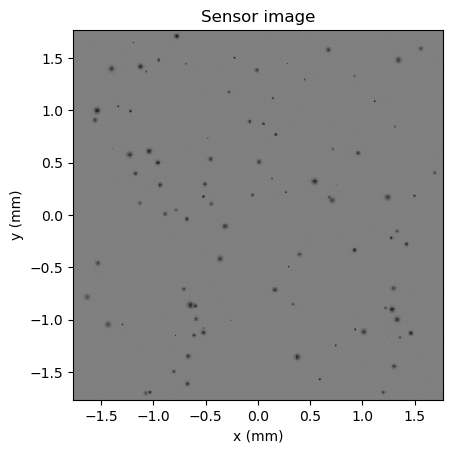

In [2]:
sensor.print_info()
sensor.transmittance = 1.

image_plane = sensor.get_image_plane()

im = sensor.capture(mp.ones(sensor_shape))
#xp.eval(im)
# display captured image in the image plane coordinate system
image_plane.imshow(im, cmap="gray", vmin=0, vmax=1)
plt.title("Sensor image")

#plt.imshow(im - sensor.capture(mp.ones(sensor_shape)))

(im - sensor.capture(mp.ones(sensor_shape))).std(), np.sqrt(32768)/32768



In [3]:
light_source.print_info()

Light source settings
----------------------
Intensity at object plane:  3600.00
Wavelength:                 532.00 nm
Bandwidth (FWHM):           29.00 nm
Frequency:                  5.64e+14 Hz
Wavenumber:                 1.18e+07 1/m
Wavenumber spread (sigma):  2.74e+05 1/m


In [4]:
microscope.print_info(full = False)

Microscope settings
----------------------
Magnification:                     60
Tube lens focal length:            2.00e-01 m
Immersion medium refractive index: 1.33
Objective numerical aperture:      0.9
Condenser numerical aperture:      0.1



## Sample setup

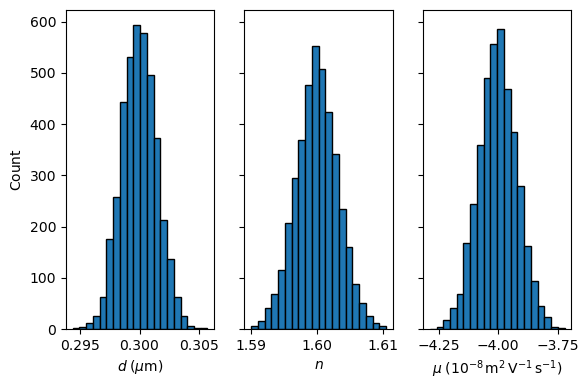

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(6, 4), sharey=True)

axes[0].hist(particles.diameter * 1e6, bins=20, edgecolor="black")
axes[0].set(xlabel=r"$d\;(\mu\mathrm{m})$", ylabel=r"$\mathrm{Count}$")

#refractive index is complex, we are only interested in the real part
axes[1].hist(particles.n_particle.real, bins=20, edgecolor="black")
axes[1].set(xlabel=r"$n$")

axes[2].hist(particles.mobility * 1e8, bins=20, edgecolor="black")
axes[2].set(
    xlabel=r"$\mu\;(10^{-8}\,\mathrm{m^2\,V^{-1}\,s^{-1}})$"
)

plt.tight_layout()

plt.savefig("distribution.pdf")
plt.savefig("distribution.png")
plt.show()


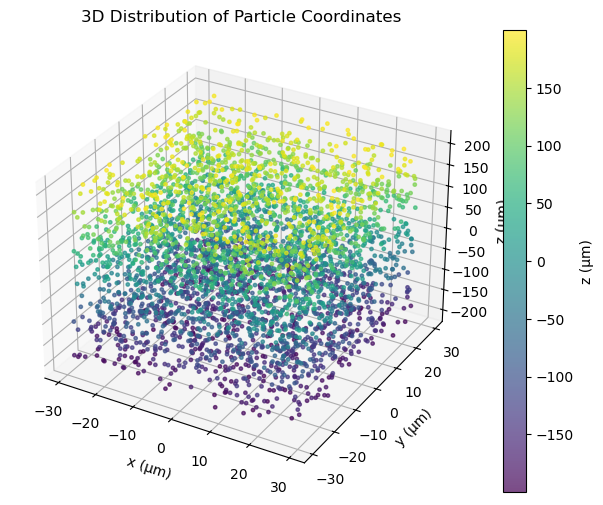

In [6]:
particles.plot_coordinates()

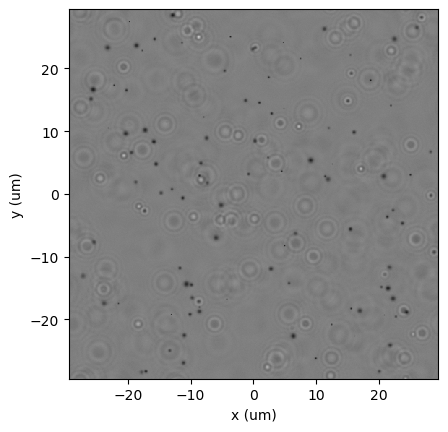

In [7]:
# Compute the lookup table for the simulator, this is a time-consuming step, but it only needs to be done once for a given set of particles and microscope settings
lut = microscope_sim.compute_lut()
# Set the depth of field for the simulator, this determines which particles are considered in focus to speed up computations
# Particles outside of this depth of field will be ignored in the simulator calculations
#microscope_sim.set_simulator_dof(100e-6)

# display image in object plane coordinate system
object_plane.imshow(mp.get_array(microscope_sim.compute_image()), cmap="gray", vmin=0, vmax=1)


## Electro-phoretic motion setup

In [8]:
ep_sim.print_info()

Experiment settings:
--------------------
Diameter mean 2.9996184025549155e-07
Mobility mean -4.0015681435079387e-08
Particle density mean 1000.0
Channel width inf
Channel height 0.00039999998989515007
Channel length inf
Pressure gradient 1.0
Fluid permittivity 80.0
Fluid density 1000.0
Fluid viscosity 0.0010000000474974513
Temperature 298.0
Gravitational acceleration [ 0.    0.   -9.81]
Sedimentation velocity mean [0. 0. 0.]
Central Poiseuille velocity 1.9999999494757503e-05

Wall zeta 0.07999999821186066
Wall mobility 5.663999402827358e-08
AC voltage 75.0
AC frequency 208.3333282470703
AC phase 0.0
Electric field 4807.6923828125

Simulator state:
----------------
Time step 9.999999747378752e-05
Flags 0
Current time 0.0
Count 0
Total simulation time 0.0
Terms 0


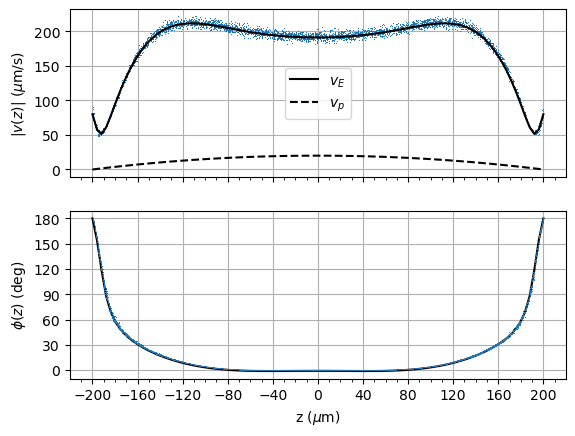

In [9]:
# plot complex the effective velocity and phase profiles of the particles in the channel

complex_mobility = ep_sim.get_complex_mobility()
coordinates = ep_sim.get_current_coordinates()

particle_zs = coordinates[:,2]
e_field = ep_sim.electric_field
channel_zs = np.linspace(-ep_sim.channel_height/2+1e-9, ep_sim.channel_height/2-1e-9, 100)
velocity_profile = eptraj.parabolic_velocity(channel_zs, ep_sim.channel_height, central_velocity) 
mobility_mean = particle_settings["mobility_mean"]

fig, axs = plt.subplots(2,1)

_xticks = np.arange(-200,201,40)

axs[0].plot(particle_zs*1000000, 1e6*e_field*np.abs(complex_mobility),"C0,")

axs[0].plot(channel_zs*1000000,1e6*e_field*np.abs(ep_sim.get_complex_mobility(z=channel_zs,mobility = mobility_mean)),"k-", label=r"$v_{E}$")

axs[0].plot(channel_zs*1000000,1e6*velocity_profile,"k--", label=r"$v_{p}$")

#axs[0].set_ylabel(r"$|\mu(z)|$ [m$^2$/Vs]")
axs[0].set_ylabel(r"$|v(z)|$ ($\mu$m/s)")
axs[0].set_xticks(_xticks)
axs[0].set_xticklabels([])
axs[0].xaxis.minorticks_on()
axs[0].grid()
axs[0].legend()
#axs[0].set_xlabel(r"z [$\mu$m]")
#axs[0].title(r"Absolute mobility")

_yticks = np.arange(0,181,30)

axs[1].plot(channel_zs*1000000,180/np.pi*np.angle(-ep_sim.get_complex_mobility(z=channel_zs,mobility = mobility_mean)),"k-")
axs[1].plot(particle_zs*1000000, 180/np.pi*np.angle(-complex_mobility),"C0,")

axs[1].set_xticks(_xticks)
axs[1].set_yticks(_yticks)
#axs[1].title(r"Relative phase")
axs[1].set_xlabel(r"z ($\mu$m)")
axs[1].set_ylabel(r"$\phi(z)$ (deg)")
axs[1].xaxis.minorticks_on()
axs[1].grid()

plt.savefig("velocities.pdf")
plt.savefig("velocities.png")   

## Build sample trajectories

In [10]:
# build test trajectories

test_trajectories = []
ep_sim.init(particles.coordinates)
for coord in ep_sim.iter_coordinates(test_count):
    test_trajectories.append(coord.copy())
test_trajectories = np.array(test_trajectories)

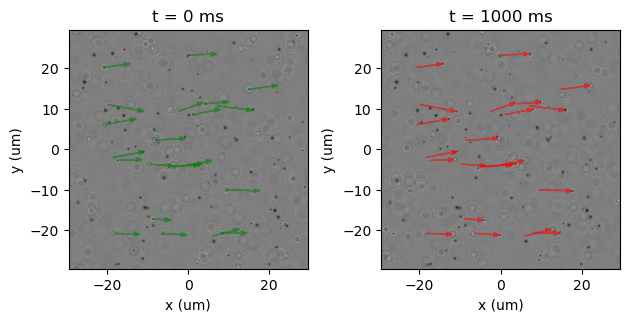

In [11]:
# plot the first and the last frame

particles.set_coordinates(test_trajectories[0])
im0 = microscope_sim.compute_image()
particles.set_coordinates(test_trajectories[-1])
im1 = microscope_sim.compute_image()
particles.set_coordinates(initial_coordinates)

from mpl_toolkits.axes_grid1 import make_axes_locatable

def add_colorbar(fig,im,ax, pad = 0.1, pack_start = False):
    # add color bar below chart
    divider = make_axes_locatable(ax)
    cax = divider.new_horizontal(size = '5%', pad = pad ,pack_start = pack_start)
    fig.add_axes(cax)
    
    fig.colorbar(im, cax = cax, orientation = 'vertical')

vmin = 0.4
vmax = 0.6

zmask = np.abs(test_trajectories[0][:,2] - microscope_sim.get_focal_plane()) < 2e-6


# we use mm units here
r0 = test_trajectories[0]*1e6
r1 = test_trajectories[-1]*1e6

images = [im0,im1]

#fig,axs = plt.subplots(1,2, figsize = (12,5))
fig,axs = plt.subplots(1,2)


im = object_plane.imshow(images[0], ax = axs[0], cmap = "gray", vmin = 0, vmax = 1)
#add_colorbar(fig,im,axs[0])
im = object_plane.imshow(images[1], ax = axs[1], cmap = "gray", vmin = 0, vmax = 1)
#add_colorbar(fig,im,axs[1])

axs[0].set_title(f"t = {0} ms")
axs[1].set_title(f"t = {1000} ms")

r0 = r0[zmask][:,0:2] # + step/2.#/step #+ (WIDTH/2, HEIGHT/2)
r1 = r1[zmask][:,0:2] # + step/2./step + (WIDTH/2, HEIGHT/2)

margin = object_plane.width/10*1e6

m0 = np.logical_and(r0[...,0] > -object_plane.width/2*1e6+ margin , r0[...,1] > -object_plane.height/2*1e6 + margin)
m1 = np.logical_and(r1[...,0] > -object_plane.width/2*1e6 +margin , r1[...,1] > -object_plane.height/2*1e6 + margin)
m2 = np.logical_and(r0[...,0] < object_plane.width/2*1e6 - margin, r0[...,1] < object_plane.height/2*1e6 - margin)
m3 = np.logical_and(r1[...,0] < object_plane.width/2*1e6 - margin, r1[...,1] < object_plane.height/2*1e6 - margin)
m = np.logical_and(m0,m1)
m = np.logical_and(m,m2)
m = np.logical_and(m,m3)

count = 0

for x0,x1 in zip(r0[m][::1],r1[m][::1]):
    count += 1
    dx = x1-x0
    #axs[0].arrow(x0[1], x0[0],dx[1],dx[0], lw = 1, alpha = 0.5, color = "r",head_width = 6,length_includes_head = True)
    axs[0].arrow(x0[0], x0[1],dx[0],dx[1], lw = 1, alpha = 0.5, color = "g",head_width = 1,length_includes_head = True)
    #axs[1].arrow(x0[1], x0[0],dx[1],dx[0], lw = 1, alpha = 0.5, color = "r",head_width = 6,length_includes_head = True)
    axs[1].arrow(x0[0], x0[1],dx[0],dx[1], lw = 1, alpha = 0.5, color = "r",head_width = 1,length_includes_head = True)


plt.tight_layout()
plt.savefig("particle_video.pdf")
plt.savefig("particle_video.png")


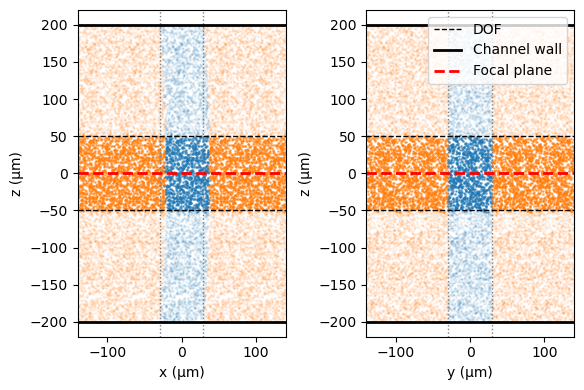

In [12]:
# plot side profile of the capillary

n_replicas_side = 2  # number of periodic copies on each side
width_um = object_plane.width * 1e6
height_um = object_plane.height * 1e6

coords_um = test_trajectories[-1] * 1e6

periods_x = width_um
periods_y = height_um

# Build replicas along x for XZ plot
replica_list_x = []
for ix in range(-n_replicas_side, n_replicas_side + 1):
    shifted = coords_um.copy()
    shifted[:, 0] += ix * periods_x
    replica_list_x.append((shifted, ix))

# Build replicas along y for YZ plot
replica_list_y = []
for iy in range(-n_replicas_side, n_replicas_side + 1):
    shifted = coords_um.copy()
    shifted[:, 1] += iy * periods_y
    replica_list_y.append((shifted, iy))

z_bottom_um = -sample_settings["channel_height"] * 1e6/2
z_top_um = sample_settings["channel_height"] * 1e6/2
# Focal plane for reference line
focal_plane_line_kwargs = dict(color="red", linestyle="--", linewidth=2)

# Reduce displayed x/y range while keeping periodic replicas for context
xy_display_half_range = 70.0*2  # ~150 um total width shown

# Focal plane for reference line
focal_plane_um = microscope_simulator_settings["focal_plane"] * 1e6

fig, axes = plt.subplots(1, 2, figsize=(6, 4))

# XZ plane
ax = axes[0]
for shifted, ix in replica_list_x:
    is_original = (ix == 0)

    shifted_rest = shifted[~microscope_sim.simulator_dof_mask]
    shifted_dof = shifted[microscope_sim.simulator_dof_mask]

    ax.scatter(
        shifted_rest[:, 0], shifted_rest[:, 2],
        s=1,
        alpha=0.08,
        color="tab:blue" if is_original else "tab:orange"
    )

    ax.scatter(
        shifted_dof[:, 0], shifted_dof[:, 2],
        s=1,
        alpha=0.5 ,
        color="tab:blue" if is_original else "tab:orange"
    )

ax.axvline(-width_um / 2, color="gray", linestyle=":", linewidth=1)
ax.axvline(width_um / 2, color="gray", linestyle=":", linewidth=1)
ax.axhline(z_bottom_um, color="black", linestyle="-", linewidth=2)
ax.axhline(z_top_um, color="black", linestyle="-", linewidth=2)
ax.axhline(focal_plane_um + microscope_sim.simulator_dof/2*1e6, color="black", linestyle="--", linewidth=1, label="DOF")
ax.axhline(focal_plane_um - microscope_sim.simulator_dof/2*1e6, color="black", linestyle="--", linewidth=1)
ax.axhline(focal_plane_um, **focal_plane_line_kwargs)

ax.set_xlim(-xy_display_half_range, xy_display_half_range)
ax.set_xlabel("x (µm)")
ax.set_ylabel("z (µm)")

ax.set_aspect("equal", adjustable="box")

# YZ plane
ax = axes[1]
for shifted, iy in replica_list_y:
    is_original = (iy == 0)
    shifted_rest = shifted[~microscope_sim.simulator_dof_mask]
    shifted_dof = shifted[microscope_sim.simulator_dof_mask]

    ax.scatter(
        shifted_rest[:, 1], shifted_rest[:, 2],
        s=1,
        alpha=0.08,
        color="tab:blue" if is_original else "tab:orange"
    )

    ax.scatter(
        shifted_dof[:, 1], shifted_dof[:, 2],
        s=1,
        alpha=0.5 ,
        color="tab:blue" if is_original else "tab:orange"
    )

ax.axvline(-height_um / 2, color="gray", linestyle=":", linewidth=1)
ax.axvline(height_um / 2, color="gray", linestyle=":", linewidth=1)
ax.axhline(z_bottom_um, color="black", linestyle="-", linewidth=2)
ax.axhline(focal_plane_um + microscope_sim.simulator_dof/2*1e6, color="black", linestyle="--", linewidth=1, label="DOF")
ax.axhline(focal_plane_um - microscope_sim.simulator_dof/2*1e6, color="black", linestyle="--", linewidth=1)
ax.axhline(z_top_um, color="black", linestyle="-", linewidth=2, label="Channel wall")
ax.axhline(focal_plane_um, label="Focal plane", **focal_plane_line_kwargs)   

ax.set_xlim(-xy_display_half_range, xy_display_half_range)
ax.set_xlabel("y (µm)")
ax.set_ylabel("z (µm)")
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right")

plt.tight_layout()
plt.savefig("simulation.pdf")
plt.savefig("simulation.png")
plt.show()


In [13]:
from ipywidgets import  IntSlider, FloatSlider, interact

def plot_image_with_controls(time, focal_plane, condenser_na, bandwidth, dof):
    """Plot simulated image with controls for focal plane, condenser NA, and source bandwidth."""
    particles.set_coordinates(test_trajectories[time]) 
    # Update optical settings
    microscope_sim.set_focal_plane(focal_plane)
    microscope_sim.set_simulator_dof(dof)
    microscope.condenser_numerical_aperture = condenser_na
    light_source.bandwidth = bandwidth 

    # Keep settings dicts in sync (optional)
    microscope_settings["condenser_numerical_aperture"] = condenser_na
    light_source_settings["bandwidth"] = bandwidth
    microscope_simulator_settings["focal_plane"] = focal_plane
    microscope_simulator_settings["simulator_dof"] = dof

    # Recompute LUT after optical changes
    im_temp = mp.get_array(microscope_sim.compute_image())

    coords_dof_um = microscope_sim.particles.coordinates[microscope_sim.simulator_dof_mask] * 1e6
    coords_um = microscope_sim.particles.coordinates[np.logical_not(microscope_sim.simulator_dof_mask)] * 1e6

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    object_plane.imshow(im_temp, ax=axes[0], cmap="gray", vmin=0, vmax=1)
    axes[0].set_title(
        f"Time: {time*ep_sim.time_step:.2f} ms | Focal: {focal_plane*1e6:.1f} µm | NA: {condenser_na:.2f} | BW: {bandwidth*1e9:.1f} nm"
    )
    axes[0].set_xlabel("x")
    axes[0].set_ylabel("y")

    axes[1].scatter(coords_um[:, 0], coords_um[:, 2], alpha=0.5, s=4, color = "C1")
    axes[1].scatter(coords_dof_um[:, 0], coords_dof_um[:, 2], alpha=0.5, s=4, color="C0")
    axes[1].axhline(focal_plane * 1e6, color="r", linestyle="--", linewidth=2, alpha=0.5)
    axes[1].axhline(sample_settings["channel_height"] * 1e6/2, color="k", linestyle="-", linewidth=2)
    axes[1].axhline(focal_plane * 1e6 - dof/2.*1e6, color="k", linestyle="--", linewidth=1, alpha=0.5)
    axes[1].axhline(focal_plane * 1e6 + dof/2.*1e6, color="k", linestyle="--", linewidth=1, alpha=0.5)
    axes[1].axhline(-sample_settings["channel_height"] * 1e6/2, color="k", linestyle="-", linewidth=2)
    axes[1].set_title("X-Z")
    axes[1].set_xlabel("x (µm)")
    axes[1].set_ylabel("z (µm)")
    axes[1].grid(True, alpha=0.3)

    axes[2].scatter(coords_um[:, 1], coords_um[:, 2], alpha=0.5, s=4, color="C1")
    axes[2].scatter(coords_dof_um[:, 1], coords_dof_um[:, 2], alpha=0.5, s=4, color="C0")
    axes[2].axhline(sample_settings["channel_height"] * 1e6/2, color="k", linestyle="-", linewidth=2)
    axes[2].axhline(focal_plane * 1e6, color="r", linestyle="--", linewidth=2, alpha=0.5)
    axes[2].axhline(focal_plane * 1e6 - dof/2.*1e6, color="k", linestyle="--", linewidth=1, alpha=0.5)
    axes[2].axhline(focal_plane * 1e6 + dof/2.*1e6, color="k", linestyle="--", linewidth=1, alpha=0.5)
    axes[2].axhline(-sample_settings["channel_height"] * 1e6/2, color="k", linestyle="-", linewidth=2)
    axes[2].set_title("Y-Z")
    axes[2].set_xlabel("y (µm)")
    axes[2].set_ylabel("z (µm)")
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

time_slider = IntSlider(
    value=0,
    min=0,
    max=len(test_trajectories) - 1,
)


focal_plane_slider = FloatSlider(
    value=microscope_simulator_settings["focal_plane"],
    min= -sample_settings["channel_height"]/2,
    max=sample_settings["channel_height"]/2,
    step=10e-6,
    description="Focal (m):",
    readout_format=".2e",
)

condenser_na_slider = FloatSlider(
    value=microscope_settings["condenser_numerical_aperture"],
    min=0.01,
    max=1.0,
    step=0.01,
    description="Cond. NA:",
    readout_format=".2f",
)

dof_slider = FloatSlider(
    value=microscope_sim.get_simulator_dof(),
    min=0,
    max=sample_settings["channel_height"],
    step=10e-6,
    description="DOF (m):",
    readout_format=".2e",
)

bandwidth_slider = FloatSlider(
    value=light_source_settings["bandwidth"],
    min=1e-9,
    max=100e-9,
    step=1e-9,
    description="BW (m):",
    readout_format=".1f",
)


interact(
    plot_image_with_controls,
    time = time_slider,
    focal_plane=focal_plane_slider,
    condenser_na=condenser_na_slider,
    bandwidth=bandwidth_slider,
    dof=dof_slider,
)

interactive(children=(IntSlider(value=0, description='time', max=3999), FloatSlider(value=0.0, description='Fo…

<function __main__.plot_image_with_controls(time, focal_plane, condenser_na, bandwidth, dof)>

In [14]:
tmask_random = random_sampling_mask(n = test_count, interval = trigger_settings["random_sampling_interval"])
tmask_regular = regular_sampling_mask(n = test_count, interval = trigger_settings["regular_sampling_interval"])
tmask_full = np.logical_or(tmask_random, tmask_regular)


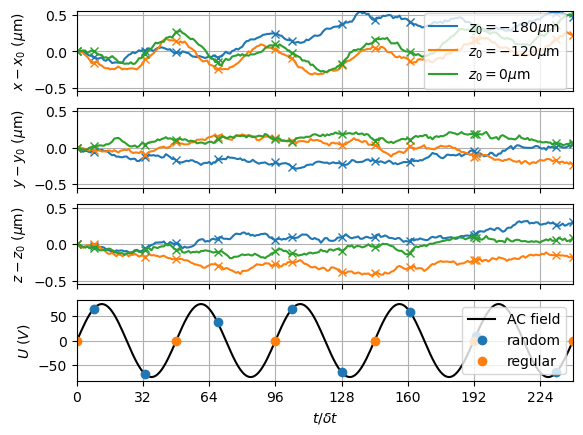

In [15]:

TMAX = 5*48

x = np.arange(0, len(test_trajectories)) 
voltage = experiment_settings["ac_voltage"]*np.sin(2*np.pi * x /experiment_settings["ac_period"]* motion_simulator_settings["time_step"] + experiment_settings["ac_phase"])


_ticks = np.arange(0, TMAX, trigger_settings["random_sampling_interval"])

tmask_test = tmask_full

trajectories_regular_test = test_trajectories
trajectories_sampled_test = trajectories_regular_test[tmask_test]

# relative displacement vector
rr = trajectories_regular_test - test_trajectories[0]
rs = trajectories_sampled_test - test_trajectories[0]
rr = rr*1e6
rs = rs*1e6

fig, axs = plt.subplots(4,1)

NT = 3

tr = np.arange(len(tmask_test))
ts = tr[tmask_test]

trmask = tr < TMAX
tsmask = ts < TMAX


XMAX = max(rr[trmask,0:NT,0:2].max(),np.abs(rr[trmask,0:NT,0:2].min()))
XMIN = -XMAX

for i in range(NT):
    z0 = trajectories_regular_test[0,i,2]*1000000
    label = f"$z_0={z0:.0f}$"+ r"$\mu$m"
    axs[0].plot(tr,rr[:,i,0], f"C{i}", label = label)
    axs[0].plot(ts,rs[:,i,0], f"xC{i}")

for i in range(NT):

    axs[1].plot(tr,rr[:,i,1], f"C{i}")
    axs[1].plot(ts,rs[:,i,1], f"xC{i}")

for i in range(NT):

    axs[2].plot(tr,rr[:,i,2], f"C{i}")
    axs[2].plot(ts,rs[:,i,2], f"xC{i}")

for i in range(0,3):
    axs[i].set_ylim(-XMAX,XMAX)
    
for i in range(0,3):

    axs[i].set_xticks(_ticks)
    #axs[i].xaxis.minorticks_on()   
    axs[i].grid()
    #axs[i].grid(which ="minor", linestyle='-.')
    axs[i].set_xlim(0, TMAX)



axs[3].plot(x, voltage, "k", label = r"AC field")

axs[3].plot(x[tmask_random], voltage[tmask_random], "o"+"C0",label = "random")
axs[3].plot(x[tmask_regular], voltage[tmask_regular], "o"+"C1", label = "regular")
#axs[3].plot(x[tmask_test],voltage[tmask_test], "k.", markerfacecolor = "w")

axs[3].set_xticks(_ticks)
axs[3].set_xlim(0, TMAX)
#axs[3].xaxis.minorticks_on()
axs[3].grid()
##axs[3].grid(which ="minor", linestyle='-.')
axs[3].set_xlabel(r"$t/\delta t$")
axs[3].legend(loc = "right")
axs[3].set_ylabel(r"$U$ ($V$)")

axs[0].legend(loc = "right")

axs[0].set_ylabel(r"$x - x_0$ ($\mu$m)")
axs[1].set_ylabel(r"$y - y_0$ ($\mu$m)")
axs[2].set_ylabel(r"$z - z_0$ ($\mu$m)")

axs[0].set_xticklabels([])
axs[1].set_xticklabels([])
axs[2].set_xticklabels([])

#axs[0].set_title("Particle trajectories")

plt.savefig("trajectories.png")
plt.savefig("trajectories.pdf")